# Cleaning and understanding the LG datasets

Explore both datasets to decide whether to keep or change the TV / LG–Samsung scope.
All numerical results come from the local CSVs; variable meanings and curation notes come from their DATA_DICTIONARY.md.


In [40]:
# 01. Import libraries
# Load the tools used for the analysis.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


In [41]:
# 02. Load behaviour
# Read the original behavioural CSV from the local data folder.
LG_DIR = Path('..') / 'data' / '01_LG_Electronics_Appliances'
raw_behavior = pd.read_csv(LG_DIR / 'electronics_market_behavior.csv')


In [42]:
# 03. Load reviews
# Read the original review CSV separately.
raw_reviews = pd.read_csv(LG_DIR / 'appliance_brand_reviews.csv')

#In the previews model we didn't use the reviews but only the behaviour

## What the two files represent

**Behaviour:** product views, carts and purchases linked by user, session and product. Includes brand, category, price and time; retailer country and currency are unidentified.

**Reviews:** appliance ratings, review text, date and purchase verification, plus product-level listing information. Review prices are in USD according to the dictionary.

The files concern different products/users and cannot be joined. Both are curated samples: their counts are not market shares. Product attributes, stock and visitor intent are unavailable for the conversion analysis.


In [43]:
# 04. Describe the files
# Compare dimensions, coverage and observed dates.
overview = pd.DataFrame({
    'dataset': ['Behaviour', 'Reviews'],
    'raw_rows': [len(raw_behavior), len(raw_reviews)],
    'columns': [raw_behavior.shape[1], raw_reviews.shape[1]],
    'brands': [raw_behavior['brand'].nunique(), raw_reviews['brand'].nunique()],
    'categories': [raw_behavior['product_category'].nunique(), raw_reviews['product_category'].nunique()],
    'products': [raw_behavior['product_id'].nunique(), raw_reviews['product_id'].nunique()],
    'first_date': [raw_behavior['event_time'].min(), raw_reviews['review_date'].min()],
    'last_date': [raw_behavior['event_time'].max(), raw_reviews['review_date'].max()]})
display(overview)
print('Distinct brands - behaviour:', raw_behavior['brand'].nunique(), '| reviews:', raw_reviews['brand'].nunique())

# Interpretation: The files have different observation units and periods; their row counts are not comparable market sizes.
# Interpretation: Reviews cover fewer brands, limiting the competitor comparisons available in that file.
# This reflects the curated sample, not the number of brands in the actual market.


,dataset,raw_rows,columns,brands,categories,products,first_date,last_date
0,Behaviour,649605,8,21,6,1613,2019-10-01 00:06:07,2019-11-30 23:56:30
1,Reviews,20004,14,8,6,2750,2004-07-12,2023-09-01


Distinct brands - behaviour: 21 | reviews: 8


In [44]:
# 05. Describe behavioral variables
# Show types, missing values and distinct values.
behavior_schema = pd.DataFrame({'type': raw_behavior.dtypes.astype(str),
    'missing': raw_behavior.isna().sum(), 'distinct_values': raw_behavior.nunique()})
display(behavior_schema)


,type,missing,distinct_values
event_time,str,0,569714
event_type,str,0,3
user_id,str,0,138863
session_id,str,0,162702
product_id,str,0,1613
product_category,str,0,6
brand,str,0,21
price,float64,0,6671


In [45]:
# 06. Describe review variables
# Show types, missing values and missing-value percentages.
review_schema = pd.DataFrame({'type': raw_reviews.dtypes.astype(str),
    'missing': raw_reviews.isna().sum(), 'distinct_values': raw_reviews.nunique()})
review_schema['missing_pct'] = 100 * review_schema['missing'] / len(raw_reviews)

display(review_schema.round(2))

# Interpretation: Missing price does not make a review unusable for every question.


,type,missing,distinct_values,missing_pct
review_id,str,0,20004,0.00
product_id,str,0,2750,0.00
brand,str,0,8,0.00
product_category,str,0,6,0.00
product_title,str,0,2637,0.00
price,float64,15883,141,79.40
product_average_rating,float64,0,40,0.00
product_rating_count,int64,0,167,0.00
review_rating,float64,0,5,0.00
review_title,str,2,16608,0.01


In [46]:
# 07. Prepare behavioural dates and prices
# Remove exact copies and convert date/price types in a working copy.
behavior = raw_behavior.drop_duplicates().copy()
behavior['event_time'] = pd.to_datetime(behavior['event_time'], utc=True, errors='coerce')
behavior['price'] = pd.to_numeric(behavior['price'], errors='coerce')


In [47]:
# 08. Standardise behavioural labels
# Make category, brand and event labels consistent and define the key.
for column in ['brand', 'product_category', 'event_type']:
    behavior[column] = behavior[column].astype('string').str.strip().str.lower().replace('', pd.NA)
key = ['user_id', 'session_id', 'product_id']


In [48]:
# 09. Separate invalid behavioural rows
# Retain unusable records separately and keep valid records for analysis.
invalid = (behavior[key + ['brand', 'product_category', 'event_time']].isna().any(axis=1)
           | ~np.isfinite(behavior['price']) | (behavior['price'] <= 0)
           | ~behavior['event_type'].isin(['view', 'cart', 'purchase']))
behavior_to_review = behavior[invalid].copy()
behavior = behavior[~invalid].copy()


In [49]:
# 10. Prepare review dates
# Remove exact copies and convert review dates.
reviews = raw_reviews.drop_duplicates().copy()
reviews['review_date'] = pd.to_datetime(reviews['review_date'], errors='coerce')


In [50]:
# 11. Standardise review fields
# Clean labels and convert numeric variables.
for column in ['brand', 'product_category']:
    reviews[column] = reviews[column].astype('string').str.strip().str.lower().replace('', pd.NA)
for column in ['price', 'review_rating', 'product_average_rating', 'product_rating_count', 'helpful_votes']:
    reviews[column] = pd.to_numeric(reviews[column], errors='coerce')


In [51]:
# 12. Separate invalid reviews
# Check identifiers, dates and ratings; flag usable prices without imputing them.
invalid = (reviews[['review_id', 'product_id', 'brand', 'product_category', 'review_date']].isna().any(axis=1)
           | ~reviews['review_rating'].isin([1, 2, 3, 4, 5]))
reviews_to_review = reviews[invalid].copy()
reviews = reviews[~invalid].copy()
assert not reviews['review_id'].duplicated().any(), 'Conflicting review IDs require investigation.'
reviews['price_usable'] = np.isfinite(reviews['price']) & (reviews['price'] > 0)


In [52]:
# 13. Report cleaning changes
# Reconcile original rows, exact copies, invalid rows and cleaned rows.
cleaning_log = pd.DataFrame({
    'dataset': ['Behaviour', 'Reviews'], 'raw_rows': [len(raw_behavior), len(raw_reviews)],
    'exact_duplicates_removed': [raw_behavior.duplicated().sum(), raw_reviews.duplicated().sum()],
    'invalid_rows_quarantined': [len(behavior_to_review), len(reviews_to_review)],
    'clean_rows': [len(behavior), len(reviews)]})
display(cleaning_log)
assert (cleaning_log['raw_rows'] - cleaning_log['exact_duplicates_removed']
        - cleaning_log['invalid_rows_quarantined']).equals(cleaning_log['clean_rows'])


,dataset,raw_rows,exact_duplicates_removed,invalid_rows_quarantined,clean_rows
0,Behaviour,649605,1247,0,648358
1,Reviews,20004,0,0,20004


In [53]:
# 14. Validate identifiers
# Check product mappings, shared session IDs and separate product systems.
assert (behavior.groupby('product_id')[['brand', 'product_category']].nunique() == 1).all().all()
assert (reviews.groupby('product_id')[['brand', 'product_category']].nunique() == 1).all().all()
print('Session IDs shared across users:', (behavior.groupby('session_id')['user_id'].nunique() > 1).sum())
print('Shared product ID labels between files:', len(set(behavior['product_id']) & set(reviews['product_id'])))

# Interpretation: Use user_id with session_id. The dictionary does not permit a join between the files.


Session IDs shared across users: 4
Shared product ID labels between files: 0


In [54]:
# 15. List available brands
# Display every brand in both cleaned files.
print('Behavioural brands:', sorted(behavior['brand'].unique()))
print('Review brands:', sorted(reviews['brand'].unique()))


Behavioural brands: ['acer', 'aoc', 'arg', 'artel', 'atlant', 'beko', 'bosch', 'dauscher', 'elenberg', 'haier', 'hp', 'indesit', 'kivi', 'lg', 'midea', 'qmax', 'samsung', 'tcl', 'tefal', 'vitek', 'xiaomi']
Review brands: ['bosch', 'electrolux', 'frigidaire', 'ge', 'haier', 'lg', 'samsung', 'whirlpool']


In [55]:
# 16. Describe behavioural categories
# Count events, users, products and brands for every category.
behavior_categories = behavior.groupby('product_category').agg(
    events=('event_type', 'size'), users=('user_id', 'nunique'),
    products=('product_id', 'nunique'), brands=('brand', 'nunique'))
display(behavior_categories.sort_values('events', ascending=False))

# Interpretation: These are sample-coverage measures, not market shares.


,events,users,products,brands
product_category,,,,
tv,211958,50373,290,6
washing_machine,161871,35711,242,6
vacuum_cleaner,117983,27551,253,6
refrigerator,108259,26554,387,6
microwave,26569,8716,76,6
monitor,21718,4778,365,6


In [56]:
# 17. Describe review categories
# Count reviews, products and brands for every category.
review_categories = reviews.groupby('product_category').agg(
    reviews=('review_id', 'size'), products=('product_id', 'nunique'), brands=('brand', 'nunique'))

display(review_categories.sort_values('reviews', ascending=False))

# Interpretation: Sampling caps limit interpretations of review counts.


,reviews,products,brands
product_category,,,
refrigerator_freezer,5834,800,8
laundry,5306,721,8
cooking,4113,827,8
other_appliance,2759,55,6
dishwasher,1959,342,7
air_conditioner,33,5,3


In [57]:
# 18. Describe event types
# Compare views, carts and purchase events across categories.
display(pd.crosstab(behavior['product_category'], behavior['event_type']))


event_type,cart,purchase,view
product_category,,,
microwave,1228,566,24775
monitor,519,192,21007
refrigerator,3339,1236,103684
tv,9706,3785,198467
vacuum_cleaner,4706,1859,111418
washing_machine,6442,2730,152699


In [58]:
# 19. Describe monthly activity
# Compare category event counts across the observed months.
behavior['month'] = behavior['event_time'].dt.strftime('%Y-%m')
display(pd.crosstab(behavior['product_category'], behavior['month']))


month,2019-10,2019-11
product_category,,
microwave,9520,17049
monitor,7747,13971
refrigerator,40987,67272
tv,72081,139877
vacuum_cleaner,39705,78278
washing_machine,62535,99336


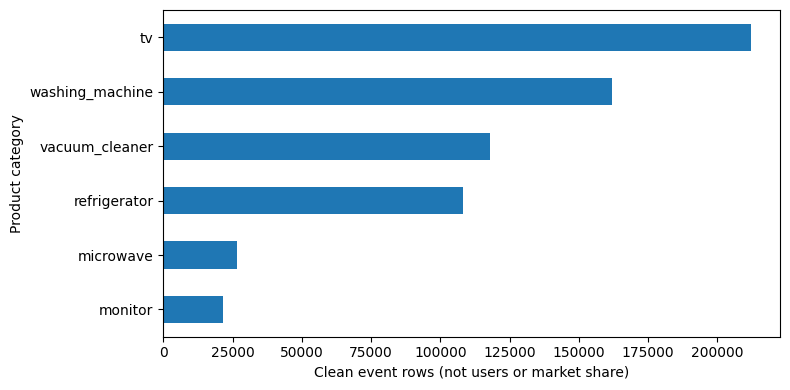

In [59]:
# 20. Plot category activity
# Visualise cleaned event counts by category.
behavior_categories['events'].sort_values().plot.barh(figsize=(8, 4))
plt.xlabel('Clean event rows (not users or market share)')
plt.ylabel('Product category')
plt.tight_layout()
plt.show()

# Interpretation: A large event count alone does not select the best research question.


In [60]:
# 21. Map behavioural brand coverage
# Show the number of observed products in each brand-category combination.
behavior_coverage = behavior.groupby(['brand', 'product_category'])['product_id'].nunique().unstack(fill_value=0)
print('Behaviour: distinct products by brand and category')
display(behavior_coverage)


Behaviour: distinct products by brand and category


product_category,microwave,monitor,refrigerator,tv,vacuum_cleaner,washing_machine
brand,,,,,,
acer,0,100,0,0,0,0
aoc,0,54,0,0,0,0
arg,4,0,0,0,0,0
artel,0,0,0,38,0,29
atlant,0,0,109,0,0,0
beko,0,0,30,0,0,23
bosch,0,0,0,0,54,0
dauscher,10,0,0,0,0,0
elenberg,5,0,0,0,0,0


In [61]:
# 22. Map review brand coverage
# Show the number of observed products in each review brand-category combination.
review_coverage = reviews.groupby(['brand', 'product_category'])['product_id'].nunique().unstack(fill_value=0)
print('Reviews: distinct products by brand and category')
display(review_coverage)

# Interpretation: Zero means no products observed in this sample, not absence from the market.


Reviews: distinct products by brand and category


product_category,air_conditioner,cooking,dishwasher,laundry,other_appliance,refrigerator_freezer
brand,,,,,,
bosch,0,71,72,31,0,16
electrolux,0,42,7,53,3,45
frigidaire,1,210,81,45,19,112
ge,2,279,87,111,12,195
haier,2,6,0,21,12,32
lg,0,57,13,186,0,165
samsung,0,81,26,138,2,166
whirlpool,0,81,56,136,7,69


## Compare categories using the same unit

One consideration is a user–session–product with at least one view. Cart and purchase outcomes must occur strictly later. A zero means no qualifying transition observed in that unit.

Using the same rules across categories makes sample support comparable; it does not establish equivalent products.


In [62]:
# 23. Find first views
# Keep the first view of each user-session-product and its initial price.
views = behavior[behavior['event_type'] == 'view']
first_views = views.sort_values('event_time', kind='stable').drop_duplicates(key)
first_views = first_views[key + ['brand', 'product_category', 'event_time', 'price']].rename(
    columns={'event_time': 'first_view', 'price': 'initial_price'})


In [63]:
# 24. Find purchase times
# Find the last purchase time in each analytical key.
purchases = behavior[behavior['event_type'] == 'purchase']
last_purchases = purchases.groupby(key)['event_time'].max().reset_index(name='last_purchase')


In [64]:
# 25. Find eligible carts
# Find the first cart strictly after the first view.
carts = behavior[behavior['event_type'] == 'cart'].merge(first_views[key + ['first_view']], on=key)
carts = carts[carts['event_time'] > carts['first_view']]
first_carts = carts.groupby(key)['event_time'].min().reset_index(name='first_cart')


In [65]:
# 26. Build considerations
# Join the events and define observed cart and purchase outcomes.
considerations = first_views.merge(last_purchases, on=key, how='left').merge(first_carts, on=key, how='left')
considerations['has_cart'] = considerations['first_cart'].notna().astype(int)
considerations['Y'] = (considerations['last_purchase'] > considerations['first_view']).astype(int)
considerations['purchase_after_cart'] = (considerations['last_purchase'] > considerations['first_cart']).astype(int)
assert not considerations.duplicated(key).any()
print('Eligible considerations across all brands/categories:', len(considerations))

# Interpretation: The same measurement rules apply to all categories and brands.


Eligible considerations across all brands/categories: 363277


In [66]:
# 27. Count category-brand outcomes
# Measure considerations, users, products and stage outcomes.
support = considerations.groupby(['product_category', 'brand']).agg(
    considerations=('Y', 'size'), users=('user_id', 'nunique'), products=('product_id', 'nunique'),
    purchases=('Y', 'sum'), carts=('has_cart', 'sum'), purchases_after_cart=('purchase_after_cart', 'sum')).reset_index()


In [67]:
# 28. Describe prices and non-conversions
# Add price quartiles and counts of observations without a stage transition.
price_summary = considerations.groupby(['product_category', 'brand'])['initial_price'].quantile([.25, .5, .75]).unstack()
price_summary.columns = ['price_p25', 'median_price', 'price_p75']
support = support.merge(price_summary.reset_index(), on=['product_category', 'brand'])
support['no_cart'] = support['considerations'] - support['carts']
support['cart_without_later_purchase'] = support['carts'] - support['purchases_after_cart']


In [68]:
# 29. Measure product concentration
# Calculate the share of considerations from the five largest products.
product_counts = considerations.groupby(['product_category', 'brand', 'product_id']).size().reset_index(name='rows')
ranked_products = product_counts.sort_values(['product_category', 'brand', 'rows', 'product_id'], ascending=[True, True, False, True])
top5 = ranked_products.groupby(['product_category', 'brand']).head(5)
top5 = top5.groupby(['product_category', 'brand'])['rows'].sum().reset_index(name='top5_rows')
support = support.merge(top5, on=['product_category', 'brand'])
support['top5_share_pct'] = 100 * support['top5_rows'] / support['considerations']
display(support.round(2))

# Interpretation: High concentration can make a brand comparison sensitive to the sampled assortment.


,product_category,brand,considerations,users,products,purchases,carts,purchases_after_cart,price_p25,median_price,price_p75,no_cart,cart_without_later_purchase,top5_rows,top5_share_pct
0,microwave,arg,3427,2934,4,160,266,114,56.60,59.18,59.18,3161,152,3427,100.00
1,microwave,dauscher,1773,1395,10,33,59,19,57.89,58.95,60.72,1714,40,1632,92.05
2,microwave,elenberg,1320,1227,5,93,91,41,50.91,51.46,51.46,1229,50,1320,100.00
3,microwave,lg,2822,2186,17,71,154,54,89.38,94.96,102.71,2668,100,2523,89.40
4,microwave,midea,1523,1292,11,44,69,29,48.65,48.88,64.07,1454,40,1335,87.66
5,microwave,samsung,4701,3045,29,150,275,113,113.77,125.87,128.45,4426,162,2947,62.69
6,monitor,acer,4614,2422,100,66,124,38,126.88,180.04,265.90,4490,86,1466,31.77
7,monitor,aoc,1099,690,54,6,14,5,137.18,230.92,324.20,1085,9,373,33.94
8,monitor,hp,1597,1093,82,24,53,13,135.65,218.54,295.76,1544,40,805,50.41
9,monitor,lg,1312,847,40,13,37,9,125.82,221.32,421.38,1275,28,418,31.86


In [69]:
# 30. Build LG comparison candidates
# Pair LG with each observed competitor within the same category.
lg_support = support[support['brand'] == 'lg'].drop(columns='brand')
others = support[support['brand'] != 'lg']
candidates = others.merge(lg_support, on='product_category', suffixes=('_competitor', '_LG'))
candidates['combined_considerations'] = candidates['considerations_competitor'] + candidates['considerations_LG']
candidates['combined_purchases'] = candidates['purchases_competitor'] + candidates['purchases_LG']


In [70]:
# 31. Compare price proximity
# Calculate median-price distance and overlap between central price ranges.
candidates['median_price_distance_pct'] = 100 * abs(candidates['median_price_competitor'] / candidates['median_price_LG'] - 1)
candidates['iqr_overlap_width'] = (candidates[['price_p75_competitor', 'price_p75_LG']].min(axis=1)
                                  - candidates[['price_p25_competitor', 'price_p25_LG']].max(axis=1)).clip(lower=0)

# Interpretation: Price proximity is a screening measure, not equivalent specifications or causal comparability.


In [71]:
# 32. Display candidate comparisons
# Show coverage, price and concentration evidence for every possible pair.
comparison_columns = ['product_category', 'brand', 'considerations_LG', 'considerations_competitor',
    'purchases_LG', 'purchases_competitor', 'products_LG', 'products_competitor',
    'median_price_LG', 'median_price_competitor', 'median_price_distance_pct',
    'iqr_overlap_width', 'top5_share_pct_LG', 'top5_share_pct_competitor']
display(candidates[comparison_columns].sort_values(['product_category', 'median_price_distance_pct']).round(2))

# Interpretation: No largest-gap ranking or automatic winner is imposed.


,product_category,brand,considerations_LG,considerations_competitor,purchases_LG,purchases_competitor,products_LG,products_competitor,median_price_LG,median_price_competitor,median_price_distance_pct,iqr_overlap_width,top5_share_pct_LG,top5_share_pct_competitor
4,microwave,samsung,2822,4701,71,150,17,29,94.96,125.87,32.55,0.00,89.40,62.69
0,microwave,arg,2822,3427,71,160,17,4,94.96,59.18,37.68,0.00,89.40,100.00
1,microwave,dauscher,2822,1773,71,33,17,10,94.96,58.95,37.92,0.00,89.40,92.05
2,microwave,elenberg,2822,1320,71,93,17,5,94.96,51.46,45.81,0.00,89.40,100.00
3,microwave,midea,2822,1523,71,44,17,11,94.96,48.88,48.53,0.00,89.40,87.66
9,monitor,samsung,1312,3718,13,59,40,61,221.32,223.63,1.04,217.91,31.86,48.52
7,monitor,hp,1312,1597,13,24,40,82,221.32,218.54,1.26,160.11,31.86,50.41
6,monitor,aoc,1312,1099,13,6,40,54,221.32,230.92,4.34,187.02,31.86,33.94
5,monitor,acer,1312,4614,13,66,40,100,221.32,180.04,18.65,139.02,31.86,31.77
8,monitor,qmax,1312,560,13,9,40,28,221.32,84.81,61.68,17.98,31.86,47.86


In [72]:
# 33. Compare Samsung across categories
# Examine the Samsung benchmark in every available LG category.
samsung_categories = candidates[candidates['brand'] == 'samsung']
display(samsung_categories[comparison_columns].sort_values('product_category').round(2))


,product_category,brand,considerations_LG,considerations_competitor,purchases_LG,purchases_competitor,products_LG,products_competitor,median_price_LG,median_price_competitor,median_price_distance_pct,iqr_overlap_width,top5_share_pct_LG,top5_share_pct_competitor
4,microwave,samsung,2822,4701,71,150,17,29,94.96,125.87,32.55,0.00,89.40,62.69
9,monitor,samsung,1312,3718,13,59,40,61,221.32,223.63,1.04,217.91,31.86,48.52
14,refrigerator,samsung,13079,9950,191,132,49,41,535.12,643.26,20.21,232.44,59.77,49.88
18,tv,samsung,22213,52499,505,1645,105,91,460.84,493.96,7.19,244.39,42.31,52.38
21,vacuum_cleaner,samsung,5493,26308,132,906,27,73,172.38,92.64,46.26,28.08,60.00,50.44
29,washing_machine,samsung,21959,32684,544,910,69,48,380.96,347.47,8.79,86.66,51.16,58.40


In [73]:
# 34. Compare competitors within TVs
# Examine all retained TV competitors using the same criteria.
tv_candidates = candidates[candidates['product_category'] == 'tv']
display(tv_candidates[comparison_columns].sort_values('median_price_distance_pct').round(2))

# Interpretation: Category choice and competitor choice require separate justification.


,product_category,brand,considerations_LG,considerations_competitor,purchases_LG,purchases_competitor,products_LG,products_competitor,median_price_LG,median_price_competitor,median_price_distance_pct,iqr_overlap_width,top5_share_pct_LG,top5_share_pct_competitor
18,tv,samsung,22213,52499,505,1645,105,91,460.84,493.96,7.19,244.39,42.31,52.38
19,tv,tcl,22213,5008,505,156,105,17,460.84,251.95,45.33,0.00,42.31,70.75
16,tv,haier,22213,9654,505,340,105,20,460.84,231.64,49.74,0.00,42.31,72.25
17,tv,kivi,22213,6465,505,222,105,19,460.84,192.93,58.14,0.00,42.31,73.78
15,tv,artel,22213,19872,505,624,105,38,460.84,154.19,66.54,0.00,42.31,83.89


In [74]:
# 35. Assess review coverage
# Show product support, dates, ratings and price/text availability.
review_support = reviews.groupby(['product_category', 'brand']).agg(
    review_rows=('review_id', 'size'), products=('product_id', 'nunique'),
    first_review=('review_date', 'min'), last_review=('review_date', 'max'),
    median_review_rating=('review_rating', 'median'), prices_available=('price_usable', 'sum'),
    text_available=('review_text', 'count')).reset_index()
review_support['price_available_pct'] = 100 * review_support['prices_available'] / review_support['review_rows']
display(review_support)


,product_category,brand,review_rows,products,first_review,last_review,median_review_rating,prices_available,text_available,price_available_pct
0,air_conditioner,frigidaire,7,1,2021-06-18,2022-04-17,5.0,7,7,100.000000
1,air_conditioner,ge,16,2,2019-09-02,2022-05-30,4.0,0,16,0.000000
2,air_conditioner,haier,10,2,2017-09-26,2021-04-08,5.0,0,10,0.000000
3,cooking,bosch,205,71,2008-01-25,2023-02-18,2.0,12,205,5.853659
4,cooking,electrolux,153,42,2008-03-21,2023-03-01,2.0,6,153,3.921569
5,cooking,frigidaire,1287,210,2006-08-30,2023-07-31,5.0,487,1287,37.839938
6,cooking,ge,1287,279,2009-01-19,2023-08-08,4.0,109,1287,8.469308
7,cooking,haier,14,6,2007-07-04,2021-03-26,3.5,0,14,0.000000
8,cooking,lg,327,57,2006-12-12,2023-05-21,4.0,19,327,5.810398
9,cooking,samsung,568,81,2009-09-09,2023-07-25,2.0,16,568,2.816901


In [75]:
# 36. Describe review ratings
# Display the observed rating distribution for each brand.
display(pd.crosstab(reviews['brand'], reviews['review_rating']))

# Interpretation: Ratings describe selected reviewers, not population defect rates.


review_rating,1.0,2.0,3.0,4.0,5.0
brand,,,,,
bosch,527,131,73,111,328
electrolux,304,63,23,46,130
frigidaire,1253,290,335,497,2202
ge,1658,384,269,434,1730
haier,258,87,127,285,1106
lg,1229,216,170,282,1026
samsung,1601,267,136,194,486
whirlpool,968,141,87,160,390


In [76]:
# 37. Describe purchase verification
# Display review verification status by brand.
display(pd.crosstab(reviews['brand'], reviews['verified_purchase']))

# Interpretation: Verification status may matter for a review question; unverified does not mean fake.


verified_purchase,False,True
brand,,
bosch,887,283
electrolux,411,155
frigidaire,806,3771
ge,1904,2571
haier,490,1373
lg,1901,1022
samsung,2270,414
whirlpool,1307,439


## Possible research directions

- **Conversion:** use observed journeys and, if appropriate, binary Logit. Check sample support, prices and concentration.
- **Satisfaction:** use appliance reviews, accounting for product coverage, periods and reviewer selection.
- **Targeting:** use browsing profiles if they lead to distinct, feasible actions.

These files alone cannot explain why visitors abandon, establish optimal discounts or measure consumer perceptions. Choose the question before adding a course method.


In [77]:
# 38. Compare LG category alternatives
# Summarise LG support across all available behavioural and review categories.
lg_categories = support[support['brand'] == 'lg']
display(lg_categories[['product_category', 'considerations', 'products', 'purchases', 'carts',
                       'purchases_after_cart', 'no_cart', 'cart_without_later_purchase', 'top5_share_pct']].round(2))
print('LG behavioural categories:', sorted(lg_categories['product_category'].unique()))
print('LG review categories:', sorted(reviews.loc[reviews['brand'] == 'lg', 'product_category'].unique()))


,product_category,considerations,products,purchases,carts,purchases_after_cart,no_cart,cart_without_later_purchase,top5_share_pct
3,microwave,2822,17,71,154,54,2668,100,89.40
9,monitor,1312,40,13,37,9,1275,28,31.86
15,refrigerator,13079,49,191,421,119,12658,302,59.77
21,tv,22213,105,505,1073,374,21140,699,42.31
25,vacuum_cleaner,5493,27,132,285,107,5208,178,60.00
33,washing_machine,21959,69,544,1018,343,20941,675,51.16


LG behavioural categories: ['microwave', 'monitor', 'refrigerator', 'tv', 'vacuum_cleaner', 'washing_machine']
LG review categories: ['cooking', 'dishwasher', 'laundry', 'refrigerator_freezer']


In [78]:
# 39. Revisit the current candidate
# Display the TV/Samsung evidence alongside the number of alternatives.
current_candidate = candidates[(candidates['product_category'] == 'tv') & (candidates['brand'] == 'samsung')]
display(current_candidate[comparison_columns].round(2))
print('Number of available LG-competitor category comparisons:', len(candidates))

# Interpretation: Use the wider comparison to decide whether to keep, refine or change this provisional scope.


,product_category,brand,considerations_LG,considerations_competitor,purchases_LG,purchases_competitor,products_LG,products_competitor,median_price_LG,median_price_competitor,median_price_distance_pct,iqr_overlap_width,top5_share_pct_LG,top5_share_pct_competitor
18,tv,samsung,22213,52499,505,1645,105,91,460.84,493.96,7.19,244.39,42.31,52.38


Number of available LG-competitor category comparisons: 30


## Group decision after exploration

Decide whether to keep, refine or change the scope. Record:

- Which managerial decision and dataset fit together?
- Why this category and competitor, compared with the alternatives shown?
- Which missing information limits the conclusion?

Use coverage, product diversity, concentration and price comparability. A large conversion gap alone does not justify the choice. TV/Samsung remains provisional until the group evaluates the evidence.
